# Figure 3

In [20]:
from riskhistory.format import rcParams
from riskhistory.data import (
    load_loo_comparison,
    load_ddm_posterior,
    DATASET_LABELS,
)
import numpy as np
import matplotlib.pyplot as plt

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]
FULL_DDM_MODEL = "HDDM_Base_Lag1-full"

### Helper functions
Refactored from `figures_draft_notebook/figure2_v3.ipynb` (Panel 4: LOO comparison; Panel 7: posterior distributions conditional on previous choice).

In [21]:
def z_link_func(x):
    return 1 / (1 + np.exp(-x))


def group_samples(posterior, param):
    return np.asarray(posterior[param]).flatten()


def compute_conditional_params(posterior):
    """Group-level MCMC posterior samples for pre-valuation bias, drift bias, and
    valuation bias (loss/gain weight ratio), each conditional on the previous
    choice (accept vs. reject), derived from HDDM_Base_Lag1-full's fitted
    terms (z_choice_prev1, v_choice_prev1, v_gain_centered:choice_prev1,
    v_loss_centered:choice_prev1)."""
    z_int = group_samples(posterior, "z_Intercept")
    z_cp1 = group_samples(posterior, "z_choice_prev1")
    v_int = group_samples(posterior, "v_Intercept")
    v_cp1 = group_samples(posterior, "v_choice_prev1")
    v_gain = group_samples(posterior, "v_gain_centered")
    v_gain_cp1 = group_samples(posterior, "v_gain_centered:choice_prev1")
    v_loss = group_samples(posterior, "v_loss_centered")
    v_loss_cp1 = group_samples(posterior, "v_loss_centered:choice_prev1")

    starting_point_accept = z_link_func(z_int + z_cp1)
    starting_point_reject = z_link_func(z_int - z_cp1)

    drift_bias_accept = v_int + v_cp1
    drift_bias_reject = v_int - v_cp1

    w_gain_accept = v_gain + v_gain_cp1
    w_gain_reject = v_gain - v_gain_cp1
    w_loss_accept = v_loss + v_loss_cp1
    w_loss_reject = v_loss - v_loss_cp1

    lambda_accept = np.abs(w_loss_accept / w_gain_accept)
    lambda_reject = np.abs(w_loss_reject / w_gain_reject)

    return {
        "Pre-Valuation Bias": (starting_point_accept, starting_point_reject),
        "Drift Bias": (drift_bias_accept, drift_bias_reject),
        "Valuation Bias": (lambda_accept, lambda_reject),
    }


def sig_stars(p):
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return "n.s."


def add_significance_bracket(ax, x1, x2, y, h, p):
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], color="black", linewidth=1.2)
    ax.text((x1 + x2) / 2, y + h, sig_stars(p), ha="center", va="bottom")

### 4x3 figure: LOO comparison and DDM posterior distributions
Columns = datasets. Row 1: DDM model comparison (LOO). Row 2: Pre-Valuation Bias posterior. Row 3: Drift Bias posterior. Row 4: Valuation Bias posterior. Rows 2-4 show HDDM_Base_Lag1-full's group-level posterior conditional on previous choice (Prev. Accept vs. Prev. Reject); the bracket's significance stars are the paired two-sided test (2*min(P(diff>0), P(diff<0))) on the per-draw accept-minus-reject difference.

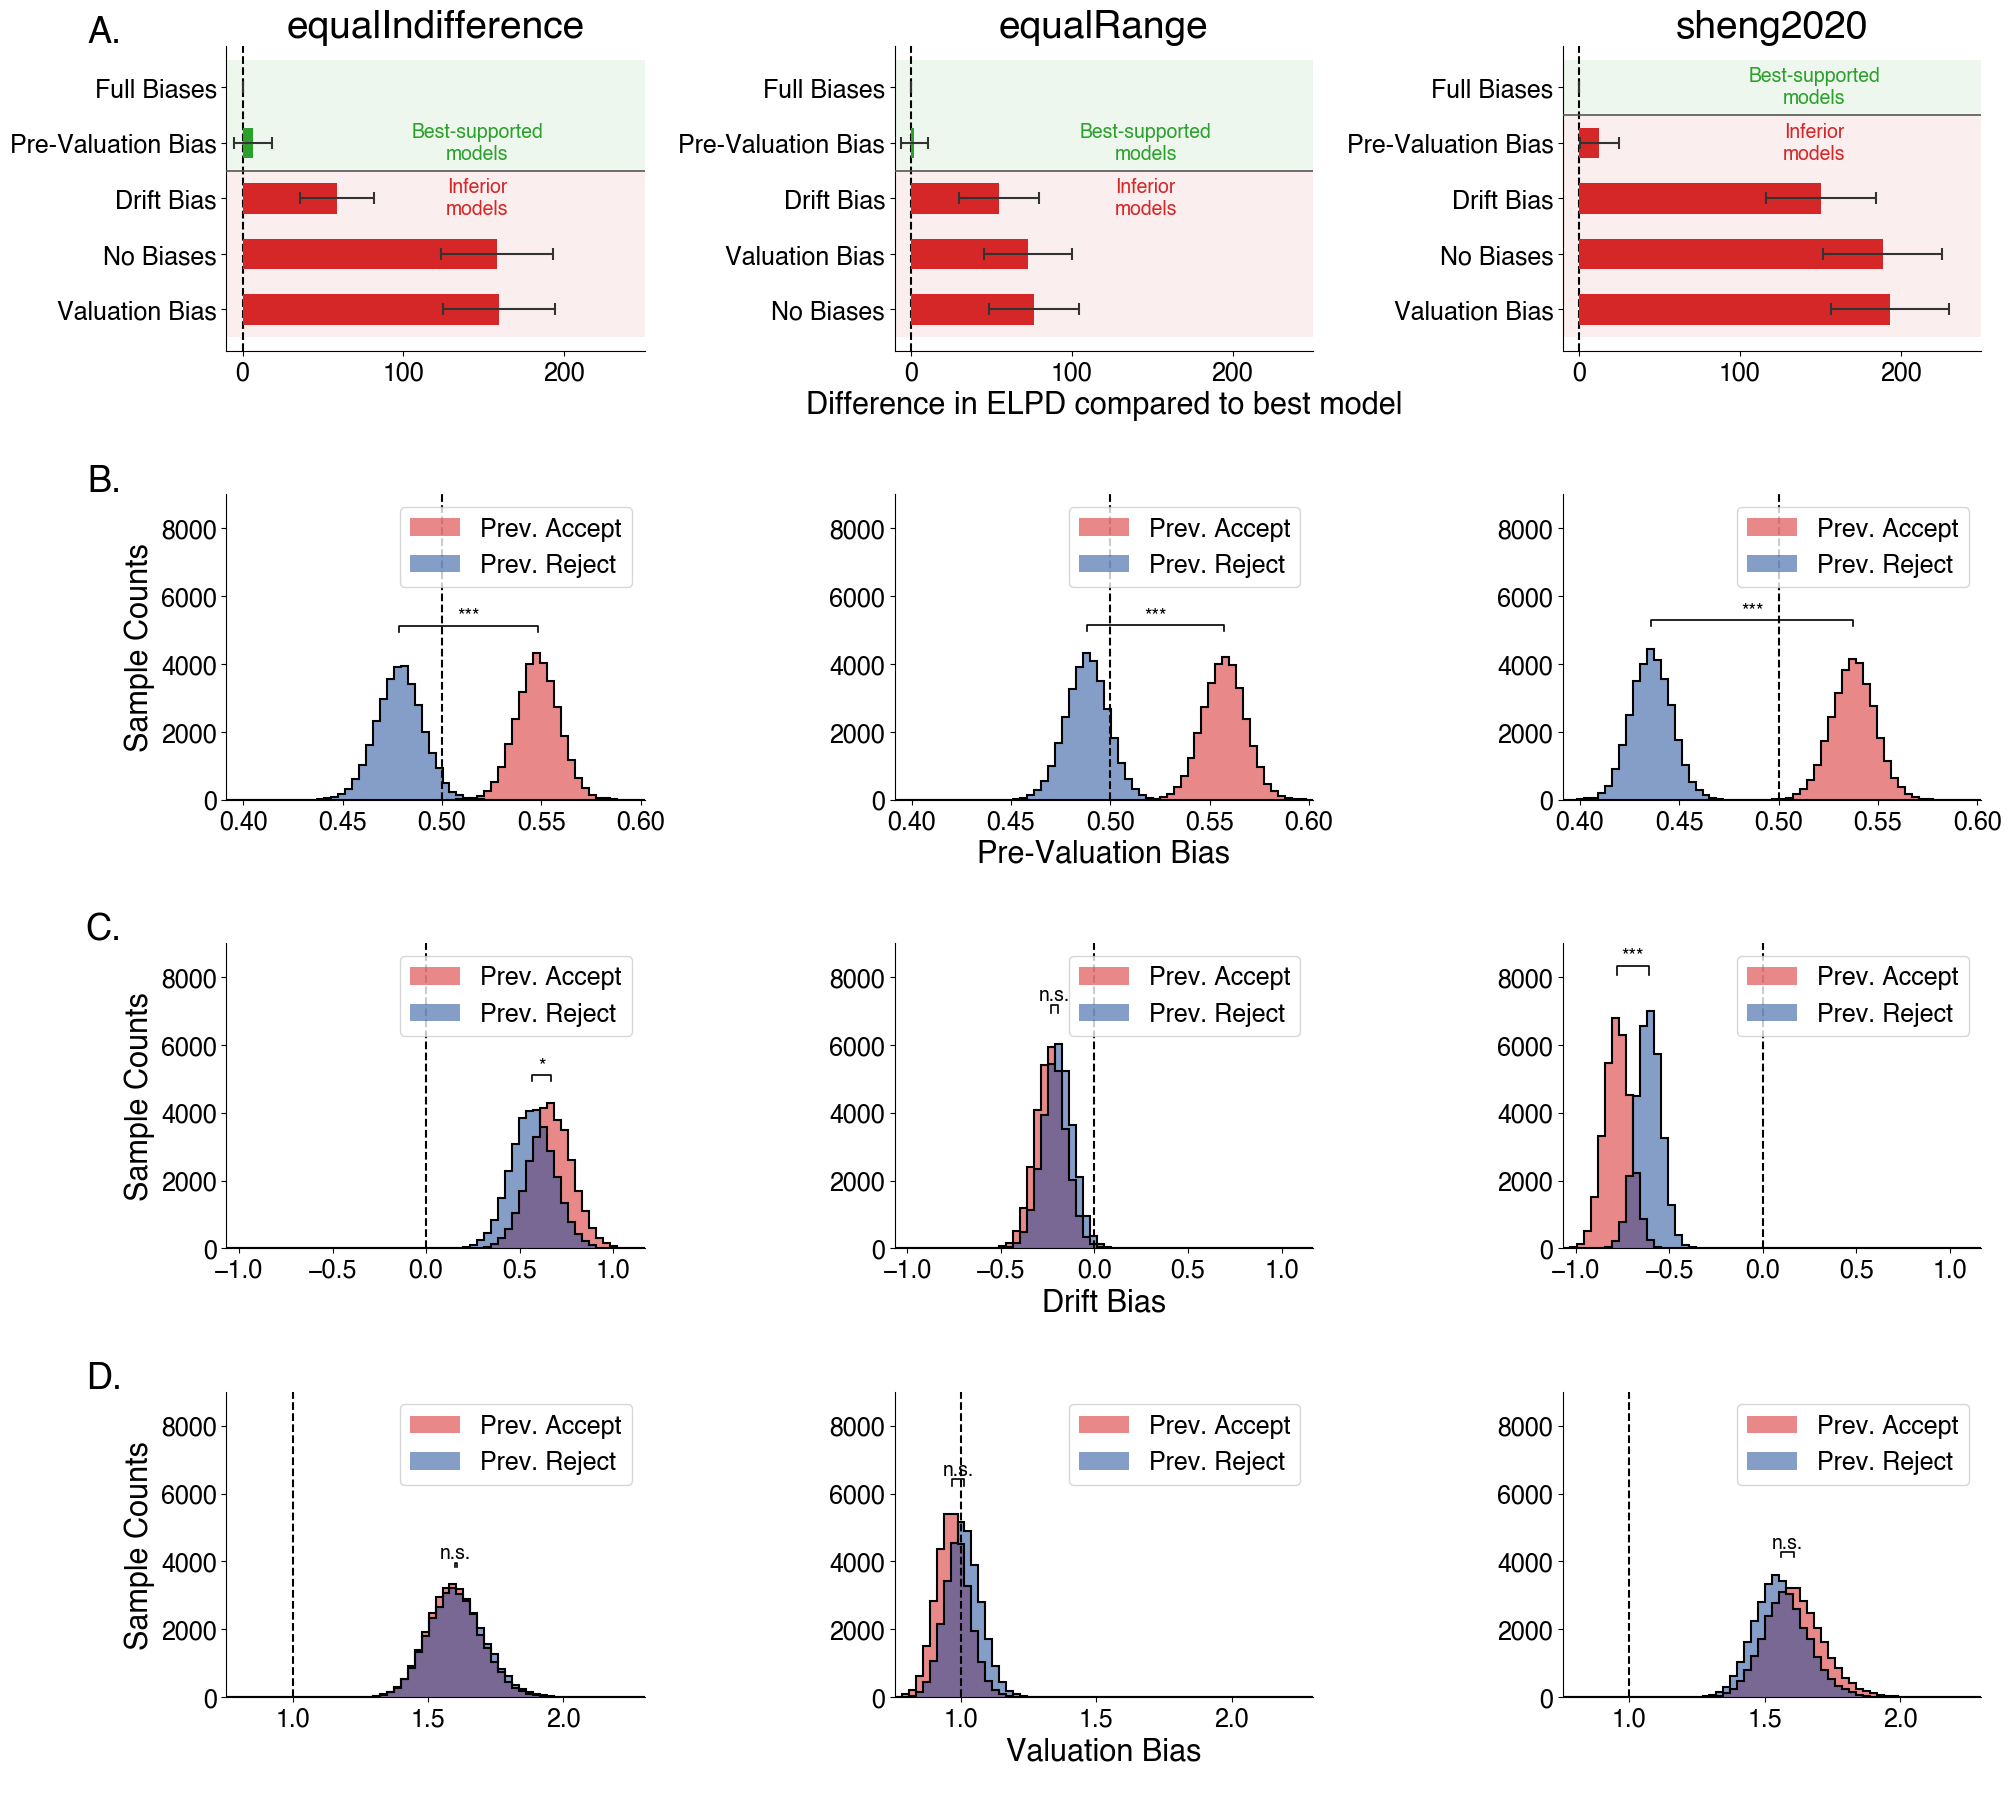

In [24]:
LOO_MODEL_LABELS = {
    "HDDM_Base":            "No Biases",
    "HDDM_Base_Lag1-stp":   "Pre-Valuation Bias",
    "HDDM_Base_Lag1-drift": "Drift Bias",
    "HDDM_Base_Lag1-stim":  "Valuation Bias",
    "HDDM_Base_Lag1-full":  "Full Biases",
}
LOO_HISTORY_COLOR = "#D62728"    # reliably worse than best
LOO_BASELINE_COLOR = "#2CA02C"   # best, or indistinguishable from best

ACCEPT_COLOR = "#D62728"
REJECT_COLOR = "#1F4E9C"

# (row_label, reference line, (text for < ref, text for > ref) or None for a
# single label centered on the reference line itself)
ROW_SPECS = [
    ("Pre-Valuation Bias", 0.5,
     None),
    ("Drift Bias", 0.0,
     None),
    ("Valuation Bias", 1.0, None),
]

posteriors = {ds: load_ddm_posterior(FULL_DDM_MODEL, ds) for ds in DATASETS}
conditional_params = {ds: compute_conditional_params(posteriors[ds]) for ds in DATASETS}

fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(20, 18), layout="constrained")

# --- Row 1: DDM model comparison (LOO) ---
for col, ds in enumerate(DATASETS):
    ax = axes[0, col]
    loo = load_loo_comparison(ds).sort_values("rank").reset_index(drop=True)

    y_pos = np.arange(len(loo))
    labels = [LOO_MODEL_LABELS.get(m, m) for m in loo["model"]]
    elpd_diff = loo["elpd_diff"].values
    dse = loo["dse"].values

    colors = []
    for i, (diff, dse_i) in enumerate(zip(elpd_diff, dse)):
        if i == 0:
            colors.append(LOO_BASELINE_COLOR)
        elif abs(diff) > 2 * dse_i:
            colors.append(LOO_HISTORY_COLOR)
        else:
            colors.append(LOO_BASELINE_COLOR)

    first_inferior = next((i for i, c in enumerate(colors) if c == LOO_HISTORY_COLOR), None)
    n = len(y_pos)
    if first_inferior is not None:
        ax.axhspan(-0.5, first_inferior - 0.5, facecolor=LOO_BASELINE_COLOR, alpha=0.08, zorder=0)
        ax.axhspan(first_inferior - 0.5, n - 0.5, facecolor=LOO_HISTORY_COLOR, alpha=0.08, zorder=0)
    else:
        ax.axhspan(-0.5, n - 0.5, facecolor=LOO_BASELINE_COLOR, alpha=0.08, zorder=0)

    ax.barh(y_pos, elpd_diff, height=0.55, color=colors, xerr=2 * dse,
            error_kw=dict(elinewidth=1.5, capsize=4, capthick=1.5, ecolor="#333333"),
            zorder=3)
    ax.axvline(0, color="black", linestyle="--", linewidth=1.5, zorder=2)

    if first_inferior is not None:
        sep = first_inferior - 0.5
        ax.axhline(sep, color="#555555", linewidth=1.2, linestyle="-", zorder=4)
        tr = ax.get_yaxis_transform()
        ax.text(0.6, sep - 0.5, "Best-supported\nmodels", transform=tr, ha="center",
               va="center", color=LOO_BASELINE_COLOR, fontstyle="italic")
        ax.text(0.6, sep + 0.5, "Inferior\nmodels", transform=tr, ha="center",
               va="center", color=LOO_HISTORY_COLOR, fontstyle="italic")

    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels)
    ax.invert_yaxis()
    if col == 1:
        ax.set_xlabel("Difference in ELPD compared to best model\n")
    ax.set_xlim(-10, 250)
    ax.set_title(DATASET_LABELS.get(ds, ds))
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# --- Rows 2-4: posterior distributions conditional on previous choice ---
for row, (row_label, ref_line, direction_labels) in enumerate(ROW_SPECS, start=1):
    row_all_samples = np.concatenate([
        np.concatenate(conditional_params[ds][row_label]) for ds in DATASETS
    ])
    row_bins = np.histogram_bin_edges(row_all_samples, bins=60)
    row_xlim = (row_all_samples.min(), row_all_samples.max())

    for col, ds in enumerate(DATASETS):
        ax = axes[row, col]
        accept_samples, reject_samples = conditional_params[ds][row_label]

        # label= is passed on every panel (not just the first) so each
        # panel's own ax.legend() call below has labeled artists to draw --
        # otherwise legend() just renders an empty frame.
        counts_accept, _, _ = ax.hist(
            accept_samples, bins=row_bins, color=ACCEPT_COLOR, alpha=0.55,
            linewidth=0.8, density=False,
            label="Prev. Accept",
        )
        ax.hist(accept_samples, bins=row_bins, histtype="step", color="black", linewidth=1.5)

        counts_reject, _, _ = ax.hist(
            reject_samples, bins=row_bins, color=REJECT_COLOR, alpha=0.55,
            linewidth=0.8, density=False,
            label="Prev. Reject",
        )
        ax.hist(reject_samples, bins=row_bins, histtype="step", color="black", linewidth=1.5)

        ax.axvline(ref_line, color="black", linestyle="--", linewidth=1.5, zorder=4)

        # Mean values are used only to anchor the bracket -- not drawn as
        # their own vertical lines.
        mean_accept = accept_samples.mean()
        mean_reject = reject_samples.mean()
        diff = accept_samples - reject_samples
        p_gt0 = (diff > 0).mean()
        p_lt0 = (diff < 0).mean()
        p_two_sided = 2 * min(p_gt0, p_lt0)

        y_max = max(counts_accept.max(), counts_reject.max())
        bracket_h = 0.04 * y_max
        bracket_y = y_max * 1.15
        x1, x2 = sorted([mean_accept, mean_reject])
        add_significance_bracket(ax, x1, x2, bracket_y, bracket_h, p_two_sided)

        ax.set_ylim(0, 9000)
        ax.set_xlim(row_xlim)


        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.legend(loc="upper right", frameon=True)
        if col == 0:
            ax.set_ylabel("Sample Counts")
        if col == 1:
            ax.set_xlabel(f"{row_label}\n")

# Row labels, placed just outside the top-left corner of each row's leftmost
# panel (same convention as figure1.ipynb's "A."/"B."/"C.")
axes[0, 0].text(-0.25, 1.1, "A.", transform=axes[0, 0].transAxes,
               fontsize=26, fontweight="bold", va="top", ha="right")
axes[1, 0].text(-0.25, 1.1, "B.", transform=axes[1, 0].transAxes,
               fontsize=26, fontweight="bold", va="top", ha="right")
axes[2, 0].text(-0.25, 1.1, "C.", transform=axes[2, 0].transAxes,
               fontsize=26, fontweight="bold", va="top", ha="right")
axes[3, 0].text(-0.25, 1.1, "D.", transform=axes[3, 0].transAxes,
               fontsize=26, fontweight="bold", va="top", ha="right")

fig.savefig("saved/figure3.svg", dpi=300, bbox_inches="tight")


plt.show()